# Pandas

The `numpy` module is excellent for numerical computations, but to handle missing data or arrays with mixed types takes more work. The `pandas` module is currently the most widely used tool for data manipulation, providing high-performance, easy-to-use data structures and advanced data analysis tools.

In particular `pandas` features:

* A fast and efficient "DataFrame" object for data manipulation with integrated indexing;
* Tools for reading and writing data between in-memory data structures and different formats (CSV, Excel, SQL, HDF5);
* Intelligent data alignment and integrated handling of missing data;
* Intelligent label-based slicing, fancy indexing, and subsetting of large data sets;
* Aggregating or transforming data with a powerful "group-by" engine; 
* High performance merging and joining of data sets;
* Hierarchical axis indexing provides an intuitive way of working with high-dimensional data in a lower-dimensional data structure;
* Time series-functionalities;
* Highly optimized for performance, with critical code paths written in Cython or C.


Allows complex operations to run vectorialy (i.e. concateneting, etc.)
If new tool comes out, you know how to deal with it.


In [3]:
import pandas as pd
import numpy as np

## Series

Series are completely equivalent to 1D array but with axis labels and the possibility to store heterogeneous elements. Of paramount importance are the time-series, used to define time evolutions of a phenomenon. 

The thing is that differentely as numpy, pandas series can store eterogenous elements.
I.e time series


In [4]:
from string import ascii_lowercase as letters

# Creating a series, accessing indexes, values and values by their index 
xs = pd.Series(np.arange(10)*0.5, index=tuple(letters[:10]))
print ("xs:", xs,'\n')
print ("xs indexes:",xs.index,'\n')
# Values of the Series are actually a numpy array
print ("xs values:", xs.values, type(xs.values),'\n')
print (xs['f'], xs.f, xs.h, '\n')
print (xs[['d', 'f', 'h']], '\n')
print (type(xs[['d', 'f', 'h']]), '\n')

xs: a    0.0
b    0.5
c    1.0
d    1.5
e    2.0
f    2.5
g    3.0
h    3.5
i    4.0
j    4.5
dtype: float64 

xs indexes: Index(['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j'], dtype='object') 

xs values: [0.  0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5] <class 'numpy.ndarray'> 

2.5 2.5 3.5 

d    1.5
f    2.5
h    3.5
dtype: float64 

<class 'pandas.core.series.Series'> 



In [5]:
# Extracting elements and operations: same as numpy array
print (xs[:3],'\n')
print (xs[7:], '\n')
print (xs[::3], '\n')
print (xs[xs>3], '\n')
print (np.exp(xs), '\n')
print (np.mean(xs), np.std(xs), '\n')
#access element

a    0.0
b    0.5
c    1.0
dtype: float64 

h    3.5
i    4.0
j    4.5
dtype: float64 

a    0.0
d    1.5
g    3.0
j    4.5
dtype: float64 

h    3.5
i    4.0
j    4.5
dtype: float64 

a     1.000000
b     1.648721
c     2.718282
d     4.481689
e     7.389056
f    12.182494
g    20.085537
h    33.115452
i    54.598150
j    90.017131
dtype: float64 

2.25 1.4361406616345072 



In [6]:
# Series can be created from python dictionary too.
# Not that the elements can be whatever!
d = {'b' : 1, 'a' : 'cat', 'c' : [2,3]}
pd.Series(d)

#keys being the indeces
#value of the series are whatever

#comment> it is good to have eterogeneous elements but not at all
# (temperature in function of time, they are all elements, same type)
#operatrion are done mathces the indeces


b         1
a       cat
c    [2, 3]
dtype: object

A key difference between Series and ndarray is that operations between Series automatically align the data based on label. Thus, you can write computations without considering whether the Series involved have the same labels.

In [8]:
s = pd.Series(np.random.randn(5), index=tuple(letters[:5]))
print(s)
s = s[1:] + s[:-1]
print(s)

# we deal with minuts, but if you study fast fenomenous you might have microseconds
#there is no unique


a    0.254602
b   -0.063038
c    1.262858
d   -0.976967
e    1.043415
dtype: float64
a         NaN
b   -0.126076
c    2.525716
d   -1.953934
e         NaN
dtype: float64
a   -0.257629
b    0.800431
c   -1.449362
d    1.481929
e   -0.335022
f    2.621759
dtype: float64


### Time series

Time series are very often used to profile the behaviour of a quantity as a function of time. Pandas has a special index for that, `DatetimeIndex`, that can be created e.g. with the function `pd.data_range()`

In [10]:
# to define a date, the datetime module is very useful
import datetime as dt
date = dt.date.today()
print(date)

date = dt.datetime(2026,11,18,10,45,10,15)
print (date)

# otherwise, several notations are interpreted too
date = 'Nov 18 2026'
# or alternatively
#date = '18/11/2026 10:45:00'
print (date)

days = pd.date_range(date, periods=7, freq='D')
print (days)

seconds = pd.date_range(date, periods=3600, freq='s')
print (seconds)


2026-11-18
2026-11-18 10:45:10.000015
Nov 18 2026
DatetimeIndex(['2026-11-18', '2026-11-19', '2026-11-20', '2026-11-21',
               '2026-11-22', '2026-11-23', '2026-11-24'],
              dtype='datetime64[ns]', freq='D')
DatetimeIndex(['2026-11-18 00:00:00', '2026-11-18 00:00:01',
               '2026-11-18 00:00:02', '2026-11-18 00:00:03',
               '2026-11-18 00:00:04', '2026-11-18 00:00:05',
               '2026-11-18 00:00:06', '2026-11-18 00:00:07',
               '2026-11-18 00:00:08', '2026-11-18 00:00:09',
               ...
               '2026-11-18 00:59:50', '2026-11-18 00:59:51',
               '2026-11-18 00:59:52', '2026-11-18 00:59:53',
               '2026-11-18 00:59:54', '2026-11-18 00:59:55',
               '2026-11-18 00:59:56', '2026-11-18 00:59:57',
               '2026-11-18 00:59:58', '2026-11-18 00:59:59'],
              dtype='datetime64[ns]', length=3600, freq='S')


To learn more about the frequency strings, please see this [link](http://pandas.pydata.org/pandas-docs/stable/timeseries.html#offset-aliases)


Timestamped data is the most basic type of time series data that associates values with points in time. For pandas objects it means using the points in time.

functions like `pd.to_datetime` can be used, for instance, when reading information as string from a dataset.

Timestamp is the pandas equivalent of python’s Datetime and is interchangeable with it in most cases. 

In [11]:
tstamp = pd.Timestamp(dt.datetime(2020, 11, 9))

# internally it counts the nanoseconds from January 1st 19
#tstamp = pd.Timestamp(dt.datetime(1970, 1, 1, 0, 0, 0, 1))
print(tstamp.value)

# when creating a timestamp the format can be explicitly passed
ts = pd.to_datetime('2010/11/12', format='%Y/%m/%d')
print (type(ts))
print (ts.value)
ts = pd.to_datetime('12-11-2010 00:00', format='%d-%m-%Y %H:%M')
print (ts)
print (ts.value)



1604880000000000000
<class 'pandas._libs.tslibs.timestamps.Timestamp'>
1289520000000000000
2010-11-12 00:00:00
1289520000000000000


A standard series can be created and (range of) elements can be used as indexes

In [12]:
tseries = pd.Series(np.random.normal(10, 1, len(days)), index=days)
# Extracting elements
print (tseries[0:4], '\n')
print (tseries['2026-11-18':'2026-12-01'], '\n') # Note - includes end time


2026-11-18     9.210087
2026-11-19     8.000876
2026-11-20    10.651348
2026-11-21     9.196938
Freq: D, dtype: float64 

2026-11-18     9.210087
2026-11-19     8.000876
2026-11-20    10.651348
2026-11-21     9.196938
2026-11-22    10.102055
2026-11-23     8.846991
2026-11-24    10.362159
Freq: D, dtype: float64 



`pd.to_datetime` can also be used to create a `DatetimeIndex`:

In [13]:
pd.to_datetime([1, 2, 3, 4], unit='D', origin=pd.Timestamp('1980-02-03'))

DatetimeIndex(['1980-02-04', '1980-02-05', '1980-02-06', '1980-02-07'], dtype='datetime64[ns]', freq=None)

## DataFrame

A pandas DataFrame is like a simple tabular spreadsheet. For future reference (or for people already familiar with R), a pandas DataFrame is very similar to the R DataFrame.

Each column in a DataFrame is a Series object.

The element can be whatever, missing data are dealt with too (as NaN)

### DataFrame creation

A DataFrame can be created implicitly, with, e.g., a DatatimeIndex object as index:

In [14]:
entries=10
dates=pd.date_range('11/18/2026 10:45:00',freq='h', periods=entries)
df = pd.DataFrame(np.random.randn(entries,4), index=dates, columns=['A','B','C','D'])
df

#colums themselves do have a label
#rows be a measurements, columns have a name, temeprature, pressure etc..

,A,B,C,D
2026-11-18 10:45:00,1.537093,-0.632582,-0.111683,0.391450
2026-11-18 11:45:00,-0.615469,2.690112,0.537021,-0.648677
2026-11-18 12:45:00,-0.240273,-1.084328,0.317593,1.533579
2026-11-18 13:45:00,2.358155,-2.642565,1.888434,-0.576999
2026-11-18 14:45:00,0.552951,2.392428,-0.823757,-0.067259
2026-11-18 15:45:00,-0.675116,1.291736,0.098880,-0.840737
2026-11-18 16:45:00,-1.016913,-1.208373,0.337552,1.290990
2026-11-18 17:45:00,1.332680,2.135558,-1.644752,-0.696175
2026-11-18 18:45:00,-0.641545,0.557421,0.778382,-0.580931
2026-11-18 19:45:00,0.216761,1.631077,-1.226031,1.601888


or by means of a dictionary:


In [15]:
df2 = pd.DataFrame(
    { 'A' : 1.,
      'B' : pd.Timestamp('20130102'),
      'C' : pd.Series(1,index=range(4),dtype='float32'),
      'D' : np.arange(7,11),
      'E' : pd.Categorical(["test","train","test","train"]),
    }
    )
df2

#if you not specify the indeces PANDAS adds indeces for every row by default

# check what happens if D and E had different lenghts 

,A,B,C,D,E
0,1.0,2013-01-02,1.0,7,test
1,1.0,2013-01-02,1.0,8,train
2,1.0,2013-01-02,1.0,9,test
3,1.0,2013-01-02,1.0,10,train


### Viewing Data

In [16]:
df.head()

,A,B,C,D
2026-11-18 10:45:00,1.537093,-0.632582,-0.111683,0.391450
2026-11-18 11:45:00,-0.615469,2.690112,0.537021,-0.648677
2026-11-18 12:45:00,-0.240273,-1.084328,0.317593,1.533579
2026-11-18 13:45:00,2.358155,-2.642565,1.888434,-0.576999
2026-11-18 14:45:00,0.552951,2.392428,-0.823757,-0.067259


In [17]:
df.tail(4)

,A,B,C,D
2026-11-18 16:45:00,-1.016913,-1.208373,0.337552,1.290990
2026-11-18 17:45:00,1.332680,2.135558,-1.644752,-0.696175
2026-11-18 18:45:00,-0.641545,0.557421,0.778382,-0.580931
2026-11-18 19:45:00,0.216761,1.631077,-1.226031,1.601888


In [18]:
df.index

DatetimeIndex(['2026-11-18 10:45:00', '2026-11-18 11:45:00',
               '2026-11-18 12:45:00', '2026-11-18 13:45:00',
               '2026-11-18 14:45:00', '2026-11-18 15:45:00',
               '2026-11-18 16:45:00', '2026-11-18 17:45:00',
               '2026-11-18 18:45:00', '2026-11-18 19:45:00'],
              dtype='datetime64[ns]', freq='H')

In [19]:
df.columns

#names of the variables

Index(['A', 'B', 'C', 'D'], dtype='object')

In [20]:
df.values

array([[ 1.53709338, -0.6325816 , -0.11168283,  0.39144968],
       [-0.61546913,  2.69011224,  0.53702054, -0.64867737],
       [-0.24027259, -1.08432759,  0.31759316,  1.53357856],
       [ 2.35815535, -2.64256492,  1.88843371, -0.57699876],
       [ 0.55295106,  2.39242802, -0.82375676, -0.06725933],
       [-0.6751156 ,  1.29173633,  0.09887979, -0.8407374 ],
       [-1.01691252, -1.20837292,  0.33755249,  1.29098983],
       [ 1.3326805 ,  2.13555842, -1.64475194, -0.69617471],
       [-0.64154523,  0.55742129,  0.77838164, -0.5809312 ],
       [ 0.2167614 ,  1.63107654, -1.22603115,  1.60188796]])

In [21]:
df.describe()

#give information per variable
#statistical information


,A,B,C,D
count,10.000000,10.000000,10.000000,10.000000
mean,0.280833,0.513049,0.015164,0.140713
std,1.135374,1.811929,1.031835,0.990343
min,-1.016913,-2.642565,-1.644752,-0.840737
25%,-0.635026,-0.971391,-0.645738,-0.631741
50%,-0.011756,0.924579,0.208236,-0.322129
75%,1.137748,2.009438,0.487154,1.066105
max,2.358155,2.690112,1.888434,1.601888


In [22]:
df.T

,2026-11-18 10:45:00,2026-11-18 11:45:00,2026-11-18 12:45:00,2026-11-18 13:45:00,2026-11-18 14:45:00,2026-11-18 15:45:00,2026-11-18 16:45:00,2026-11-18 17:45:00,2026-11-18 18:45:00,2026-11-18 19:45:00
A,1.537093,-0.615469,-0.240273,2.358155,0.552951,-0.675116,-1.016913,1.332680,-0.641545,0.216761
B,-0.632582,2.690112,-1.084328,-2.642565,2.392428,1.291736,-1.208373,2.135558,0.557421,1.631077
C,-0.111683,0.537021,0.317593,1.888434,-0.823757,0.098880,0.337552,-1.644752,0.778382,-1.226031
D,0.391450,-0.648677,1.533579,-0.576999,-0.067259,-0.840737,1.290990,-0.696175,-0.580931,1.601888


In [23]:
df.sort_index(axis=0,ascending=False)

,A,B,C,D
2026-11-18 19:45:00,0.216761,1.631077,-1.226031,1.601888
2026-11-18 18:45:00,-0.641545,0.557421,0.778382,-0.580931
2026-11-18 17:45:00,1.332680,2.135558,-1.644752,-0.696175
2026-11-18 16:45:00,-1.016913,-1.208373,0.337552,1.290990
2026-11-18 15:45:00,-0.675116,1.291736,0.098880,-0.840737
2026-11-18 14:45:00,0.552951,2.392428,-0.823757,-0.067259
2026-11-18 13:45:00,2.358155,-2.642565,1.888434,-0.576999
2026-11-18 12:45:00,-0.240273,-1.084328,0.317593,1.533579
2026-11-18 11:45:00,-0.615469,2.690112,0.537021,-0.648677
2026-11-18 10:45:00,1.537093,-0.632582,-0.111683,0.391450


In [24]:
df.sort_values(by="C")

,A,B,C,D
2026-11-18 17:45:00,1.332680,2.135558,-1.644752,-0.696175
2026-11-18 19:45:00,0.216761,1.631077,-1.226031,1.601888
2026-11-18 14:45:00,0.552951,2.392428,-0.823757,-0.067259
2026-11-18 10:45:00,1.537093,-0.632582,-0.111683,0.391450
2026-11-18 15:45:00,-0.675116,1.291736,0.098880,-0.840737
2026-11-18 12:45:00,-0.240273,-1.084328,0.317593,1.533579
2026-11-18 16:45:00,-1.016913,-1.208373,0.337552,1.290990
2026-11-18 11:45:00,-0.615469,2.690112,0.537021,-0.648677
2026-11-18 18:45:00,-0.641545,0.557421,0.778382,-0.580931
2026-11-18 13:45:00,2.358155,-2.642565,1.888434,-0.576999


## Selection

### Getting slices

The following show how to get part of the DataFrame (i.e. not just the elements)

In [25]:
## standard and safe
print (df['A'],'\n')
#key> use this all the time

## equivalent but dangerous (imagine blank spaces in the name of the column..)
print (df.A)



2026-11-18 10:45:00    1.537093
2026-11-18 11:45:00   -0.615469
2026-11-18 12:45:00   -0.240273
2026-11-18 13:45:00    2.358155
2026-11-18 14:45:00    0.552951
2026-11-18 15:45:00   -0.675116
2026-11-18 16:45:00   -1.016913
2026-11-18 17:45:00    1.332680
2026-11-18 18:45:00   -0.641545
2026-11-18 19:45:00    0.216761
Freq: H, Name: A, dtype: float64 

2026-11-18 10:45:00    1.537093
2026-11-18 11:45:00   -0.615469
2026-11-18 12:45:00   -0.240273
2026-11-18 13:45:00    2.358155
2026-11-18 14:45:00    0.552951
2026-11-18 15:45:00   -0.675116
2026-11-18 16:45:00   -1.016913
2026-11-18 17:45:00    1.332680
2026-11-18 18:45:00   -0.641545
2026-11-18 19:45:00    0.216761
Freq: H, Name: A, dtype: float64


In [26]:
# selecting rows by counting
print (df[0:3])

# or by index
print (df["2026-11-18 10:45:00":"2026-11-18 12:45:00"]) #specifically
#or you can select columns

                            A         B         C         D
2026-11-18 10:45:00  1.537093 -0.632582 -0.111683  0.391450
2026-11-18 11:45:00 -0.615469  2.690112  0.537021 -0.648677
2026-11-18 12:45:00 -0.240273 -1.084328  0.317593  1.533579
                            A         B         C         D
2026-11-18 10:45:00  1.537093 -0.632582 -0.111683  0.391450
2026-11-18 11:45:00 -0.615469  2.690112  0.537021 -0.648677
2026-11-18 12:45:00 -0.240273 -1.084328  0.317593  1.533579


### Selection by label

In [27]:
# getting a cross section (part of the DataFrame) using a label
df.loc[dates[0]]

#there are some reduntansence about to access to indeces


A    1.537093
B   -0.632582
C   -0.111683
D    0.391450
Name: 2026-11-18 10:45:00, dtype: float64

In [28]:
# selecting on a multi-axis by label:
df.loc[:"2026-11-18 12:45:00",['A','B']]
#a=df.loc[:,['A','B']]

,A,B
2026-11-18 10:45:00,1.537093,-0.632582
2026-11-18 11:45:00,-0.615469,2.690112
2026-11-18 12:45:00,-0.240273,-1.084328


In [29]:
# showing label slicing, both endpoints are included:
df.loc['2026-11-18 14:45:00':'2026-11-18 16:45:00',['A','B']]

,A,B
2026-11-18 14:45:00,0.552951,2.392428
2026-11-18 15:45:00,-0.675116,1.291736
2026-11-18 16:45:00,-1.016913,-1.208373


In [30]:
# getting an individual element
print (df.loc[dates[1],'A'])

# equivalently
print (df.at[dates[1],'A'])

-0.615469129904131
-0.615469129904131


### Selecting by position

In [31]:
# select via the position of the passed integers:
print (df.iloc[3],'\n')

# notation similar to numpy/python
print (df.iloc[3:5,0:2])

#df.iloc specifyng two ranges or the position

A    2.358155
B   -2.642565
C    1.888434
D   -0.576999
Name: 2026-11-18 13:45:00, dtype: float64 

                            A         B
2026-11-18 13:45:00  2.358155 -2.642565
2026-11-18 14:45:00  0.552951  2.392428


In [32]:
# selecting raws 1,2 and 4 for columns 0 and 2
df.iloc[[1,2,4],[0,2]]

#select non conntinous columns or rows

,A,C
2026-11-18 11:45:00,-0.615469,0.537021
2026-11-18 12:45:00,-0.240273,0.317593
2026-11-18 14:45:00,0.552951,-0.823757


In [33]:
# slicing rows explicitly
print (df.iloc[1:3,:],'\n')

# slicing columns explicitly
print (df.iloc[:,1:3])

# selecting an individual element by position
print(df.iloc[1,1])

#you are interested in only subregion

                            A         B         C         D
2026-11-18 11:45:00 -0.615469  2.690112  0.537021 -0.648677
2026-11-18 12:45:00 -0.240273 -1.084328  0.317593  1.533579 

                            B         C
2026-11-18 10:45:00 -0.632582 -0.111683
2026-11-18 11:45:00  2.690112  0.537021
2026-11-18 12:45:00 -1.084328  0.317593
2026-11-18 13:45:00 -2.642565  1.888434
2026-11-18 14:45:00  2.392428 -0.823757
2026-11-18 15:45:00  1.291736  0.098880
2026-11-18 16:45:00 -1.208373  0.337552
2026-11-18 17:45:00  2.135558 -1.644752
2026-11-18 18:45:00  0.557421  0.778382
2026-11-18 19:45:00  1.631077 -1.226031
2.690112243605593


### Boolean index

Very powerful way of filtering out data with certain features. Notation is very similar to numpy arrays.

In [34]:
# Filter by a boolean condition on the values of a single column
df[df['B'] > 0]

#you do that istead of doing a for cycle, amazing

,A,B,C,D
2026-11-18 11:45:00,-0.615469,2.690112,0.537021,-0.648677
2026-11-18 14:45:00,0.552951,2.392428,-0.823757,-0.067259
2026-11-18 15:45:00,-0.675116,1.291736,0.098880,-0.840737
2026-11-18 17:45:00,1.332680,2.135558,-1.644752,-0.696175
2026-11-18 18:45:00,-0.641545,0.557421,0.778382,-0.580931
2026-11-18 19:45:00,0.216761,1.631077,-1.226031,1.601888


In [35]:
# Selecting on the basis of boolean conditions applied to the whole DataFrame
df[df>0]

# a DataFrame with the same shape is returned, with NaN's where condition is not met

,A,B,C,D
2026-11-18 10:45:00,1.537093,NaN,NaN,0.391450
2026-11-18 11:45:00,NaN,2.690112,0.537021,NaN
2026-11-18 12:45:00,NaN,NaN,0.317593,1.533579
2026-11-18 13:45:00,2.358155,NaN,1.888434,NaN
2026-11-18 14:45:00,0.552951,2.392428,NaN,NaN
2026-11-18 15:45:00,NaN,1.291736,0.098880,NaN
2026-11-18 16:45:00,NaN,NaN,0.337552,1.290990
2026-11-18 17:45:00,1.332680,2.135558,NaN,NaN
2026-11-18 18:45:00,NaN,0.557421,0.778382,NaN
2026-11-18 19:45:00,0.216761,1.631077,NaN,1.601888


### Setting

Combination of selection and setting of values

Tipically want to do is not to add another data to what you are manage computationally.
People might have to modify the data they manage.

You use df.at
You create a new column: df['E prime'] = pd.Series(..)

In [36]:
# setting values by label (same as by position)
df.at[dates[0],'A'] = 0

# setting and assigning a numpy array
df.loc[:,'D'] = np.array([5] * len(df))

# defining a brend new column
df['E'] = np.arange(len(df))*0.5

# defining a brend new column by means of a pd.Series: indexes must be the same!
df['E prime'] = pd.Series(np.arange(len(df))*2, index=df.index)

df

#super efficient computationally 

,A,B,C,D,E,E prime
2026-11-18 10:45:00,0.000000,-0.632582,-0.111683,5,0.0,0
2026-11-18 11:45:00,-0.615469,2.690112,0.537021,5,0.5,2
2026-11-18 12:45:00,-0.240273,-1.084328,0.317593,5,1.0,4
2026-11-18 13:45:00,2.358155,-2.642565,1.888434,5,1.5,6
2026-11-18 14:45:00,0.552951,2.392428,-0.823757,5,2.0,8
2026-11-18 15:45:00,-0.675116,1.291736,0.098880,5,2.5,10
2026-11-18 16:45:00,-1.016913,-1.208373,0.337552,5,3.0,12
2026-11-18 17:45:00,1.332680,2.135558,-1.644752,5,3.5,14
2026-11-18 18:45:00,-0.641545,0.557421,0.778382,5,4.0,16
2026-11-18 19:45:00,0.216761,1.631077,-1.226031,5,4.5,18


In [37]:
def dcos(theta):
    theta = theta*(np.pi/180)
    return np.cos(theta)
 
df['cosine'] = pd.Series(df["E"].apply(dcos), index=df.index)
df

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.632582,-0.111683,5,0.0,0,1.000000
2026-11-18 11:45:00,-0.615469,2.690112,0.537021,5,0.5,2,0.999962
2026-11-18 12:45:00,-0.240273,-1.084328,0.317593,5,1.0,4,0.999848
2026-11-18 13:45:00,2.358155,-2.642565,1.888434,5,1.5,6,0.999657
2026-11-18 14:45:00,0.552951,2.392428,-0.823757,5,2.0,8,0.999391
2026-11-18 15:45:00,-0.675116,1.291736,0.098880,5,2.5,10,0.999048
2026-11-18 16:45:00,-1.016913,-1.208373,0.337552,5,3.0,12,0.998630
2026-11-18 17:45:00,1.332680,2.135558,-1.644752,5,3.5,14,0.998135
2026-11-18 18:45:00,-0.641545,0.557421,0.778382,5,4.0,16,0.997564
2026-11-18 19:45:00,0.216761,1.631077,-1.226031,5,4.5,18,0.996917


In [38]:
# another example of global setting
df2=df.copy()

df2[df2>0] = -df2
df2

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.632582,-0.111683,-5,0.0,0,-1.000000
2026-11-18 11:45:00,-0.615469,-2.690112,-0.537021,-5,-0.5,-2,-0.999962
2026-11-18 12:45:00,-0.240273,-1.084328,-0.317593,-5,-1.0,-4,-0.999848
2026-11-18 13:45:00,-2.358155,-2.642565,-1.888434,-5,-1.5,-6,-0.999657
2026-11-18 14:45:00,-0.552951,-2.392428,-0.823757,-5,-2.0,-8,-0.999391
2026-11-18 15:45:00,-0.675116,-1.291736,-0.098880,-5,-2.5,-10,-0.999048
2026-11-18 16:45:00,-1.016913,-1.208373,-0.337552,-5,-3.0,-12,-0.998630
2026-11-18 17:45:00,-1.332680,-2.135558,-1.644752,-5,-3.5,-14,-0.998135
2026-11-18 18:45:00,-0.641545,-0.557421,-0.778382,-5,-4.0,-16,-0.997564
2026-11-18 19:45:00,-0.216761,-1.631077,-1.226031,-5,-4.5,-18,-0.996917


### Are you dealing with a Copy or a View?

In general is hard to tell..

In [39]:
dfd = pd.DataFrame({'a': [1, 2, 3], 'b': [4, 5, 6]})

# This is likely a view
subset = dfd.loc[0:1, 'a']  
subset[0] = 100  # May affect `df`

print (dfd)

# This is a copy
subset = dfd.loc[[0, 1], 'a']  
subset[0] = 200  # Does NOT affect `df`

print (dfd)



     a  b
0  100  4
1    2  5
2    3  6
     a  b
0  100  4
1    2  5
2    3  6


The behaviour depend on the version of Pandas and on the version of Numpy that given version of Pandas depends upon. Since Pandas 1.5 "Copy-on-Write" (CoW) is (optionally) available and as of Pandas 3.0 will be the default. 

With CoW chained assignemt will never work; in the following example, the view `dfd["a"]` and `df` itself are modified in one step. This will lead to a `ChainedAssignemntError`  

In [78]:
dfd["a"][dfd["b"] > 5] = 100
dfd

#nested kind of settings

,a,b
0,100,4
1,2,5
2,100,6


With copy on write this can be done by using `loc`

In [79]:
dfd.loc[dfd["b"] > 5, "a"] = 200
dfd

,a,b
0,100,4
1,2,5
2,200,6


### Dropping

N.B.: dropping doesn't act permanently on the DataFrame, i.e. to get that do :
```python
df = df.drop(....)
```

In [42]:
# Dropping by column
df.drop(['E prime'], axis=1)

#which is equivalent to
new_df=df.drop(columns=['E prime'])
new_df

,A,B,C,D,E,cosine
2026-11-18 10:45:00,0.000000,-0.632582,-0.111683,5,0.0,1.000000
2026-11-18 11:45:00,-0.615469,2.690112,0.537021,5,0.5,0.999962
2026-11-18 12:45:00,-0.240273,-1.084328,0.317593,5,1.0,0.999848
2026-11-18 13:45:00,2.358155,-2.642565,1.888434,5,1.5,0.999657
2026-11-18 14:45:00,0.552951,2.392428,-0.823757,5,2.0,0.999391
2026-11-18 15:45:00,-0.675116,1.291736,0.098880,5,2.5,0.999048
2026-11-18 16:45:00,-1.016913,-1.208373,0.337552,5,3.0,0.998630
2026-11-18 17:45:00,1.332680,2.135558,-1.644752,5,3.5,0.998135
2026-11-18 18:45:00,-0.641545,0.557421,0.778382,5,4.0,0.997564
2026-11-18 19:45:00,0.216761,1.631077,-1.226031,5,4.5,0.996917


In [43]:
# Dropping by raws
# safe and always working
df.drop(df.index[[1,2,3,4]])

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.632582,-0.111683,5,0.0,0,1.000000
2026-11-18 15:45:00,-0.675116,1.291736,0.098880,5,2.5,10,0.999048
2026-11-18 16:45:00,-1.016913,-1.208373,0.337552,5,3.0,12,0.998630
2026-11-18 17:45:00,1.332680,2.135558,-1.644752,5,3.5,14,0.998135
2026-11-18 18:45:00,-0.641545,0.557421,0.778382,5,4.0,16,0.997564
2026-11-18 19:45:00,0.216761,1.631077,-1.226031,5,4.5,18,0.996917


In [44]:
df

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.632582,-0.111683,5,0.0,0,1.000000
2026-11-18 11:45:00,-0.615469,2.690112,0.537021,5,0.5,2,0.999962
2026-11-18 12:45:00,-0.240273,-1.084328,0.317593,5,1.0,4,0.999848
2026-11-18 13:45:00,2.358155,-2.642565,1.888434,5,1.5,6,0.999657
2026-11-18 14:45:00,0.552951,2.392428,-0.823757,5,2.0,8,0.999391
2026-11-18 15:45:00,-0.675116,1.291736,0.098880,5,2.5,10,0.999048
2026-11-18 16:45:00,-1.016913,-1.208373,0.337552,5,3.0,12,0.998630
2026-11-18 17:45:00,1.332680,2.135558,-1.644752,5,3.5,14,0.998135
2026-11-18 18:45:00,-0.641545,0.557421,0.778382,5,4.0,16,0.997564
2026-11-18 19:45:00,0.216761,1.631077,-1.226031,5,4.5,18,0.996917


In [45]:
# something like df.drop('index_name') 
# would work but the type of index must be specificed, 
# in particular with DatetimeIndex
df.drop(pd.to_datetime("2026-11-18 18:45:00"))

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.632582,-0.111683,5,0.0,0,1.000000
2026-11-18 11:45:00,-0.615469,2.690112,0.537021,5,0.5,2,0.999962
2026-11-18 12:45:00,-0.240273,-1.084328,0.317593,5,1.0,4,0.999848
2026-11-18 13:45:00,2.358155,-2.642565,1.888434,5,1.5,6,0.999657
2026-11-18 14:45:00,0.552951,2.392428,-0.823757,5,2.0,8,0.999391
2026-11-18 15:45:00,-0.675116,1.291736,0.098880,5,2.5,10,0.999048
2026-11-18 16:45:00,-1.016913,-1.208373,0.337552,5,3.0,12,0.998630
2026-11-18 17:45:00,1.332680,2.135558,-1.644752,5,3.5,14,0.998135
2026-11-18 19:45:00,0.216761,1.631077,-1.226031,5,4.5,18,0.996917


## Missing data

pandas primarily uses the value np.nan to represent missing data. It is by default not included in computations.

In [46]:
df_wNan = df[df>-0.5]
df_wNan

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,NaN,-0.111683,5,0.0,0,1.000000
2026-11-18 11:45:00,NaN,2.690112,0.537021,5,0.5,2,0.999962
2026-11-18 12:45:00,-0.240273,NaN,0.317593,5,1.0,4,0.999848
2026-11-18 13:45:00,2.358155,NaN,1.888434,5,1.5,6,0.999657
2026-11-18 14:45:00,0.552951,2.392428,NaN,5,2.0,8,0.999391
2026-11-18 15:45:00,NaN,1.291736,0.098880,5,2.5,10,0.999048
2026-11-18 16:45:00,NaN,NaN,0.337552,5,3.0,12,0.998630
2026-11-18 17:45:00,1.332680,2.135558,NaN,5,3.5,14,0.998135
2026-11-18 18:45:00,NaN,0.557421,0.778382,5,4.0,16,0.997564
2026-11-18 19:45:00,0.216761,1.631077,NaN,5,4.5,18,0.996917


In [47]:
# dropping raws with at least a Nan
df_wNan.dropna(how='any')

,A,B,C,D,E,E prime,cosine


In [48]:
# getting a mask
df_wNan.isna()
#df_wNan.notna()

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,False,True,False,False,False,False,False
2026-11-18 11:45:00,True,False,False,False,False,False,False
2026-11-18 12:45:00,False,True,False,False,False,False,False
2026-11-18 13:45:00,False,True,False,False,False,False,False
2026-11-18 14:45:00,False,False,True,False,False,False,False
2026-11-18 15:45:00,True,False,False,False,False,False,False
2026-11-18 16:45:00,True,True,False,False,False,False,False
2026-11-18 17:45:00,False,False,True,False,False,False,False
2026-11-18 18:45:00,True,False,False,False,False,False,False
2026-11-18 19:45:00,False,False,True,False,False,False,False


In [49]:
# filling missing data
df_wNan.fillna(value=0)

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,0.000000,-0.111683,5,0.0,0,1.000000
2026-11-18 11:45:00,0.000000,2.690112,0.537021,5,0.5,2,0.999962
2026-11-18 12:45:00,-0.240273,0.000000,0.317593,5,1.0,4,0.999848
2026-11-18 13:45:00,2.358155,0.000000,1.888434,5,1.5,6,0.999657
2026-11-18 14:45:00,0.552951,2.392428,0.000000,5,2.0,8,0.999391
2026-11-18 15:45:00,0.000000,1.291736,0.098880,5,2.5,10,0.999048
2026-11-18 16:45:00,0.000000,0.000000,0.337552,5,3.0,12,0.998630
2026-11-18 17:45:00,1.332680,2.135558,0.000000,5,3.5,14,0.998135
2026-11-18 18:45:00,0.000000,0.557421,0.778382,5,4.0,16,0.997564
2026-11-18 19:45:00,0.216761,1.631077,0.000000,5,4.5,18,0.996917


Fill gaps forward or backward by propagating non-NA values forward or backward:

In [50]:
df_wNan.fillna(method='pad')

#exstimate what are the missed data
#or pandas offers df_wNan

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,NaN,-0.111683,5,0.0,0,1.000000
2026-11-18 11:45:00,0.000000,2.690112,0.537021,5,0.5,2,0.999962
2026-11-18 12:45:00,-0.240273,2.690112,0.317593,5,1.0,4,0.999848
2026-11-18 13:45:00,2.358155,2.690112,1.888434,5,1.5,6,0.999657
2026-11-18 14:45:00,0.552951,2.392428,1.888434,5,2.0,8,0.999391
2026-11-18 15:45:00,0.552951,1.291736,0.098880,5,2.5,10,0.999048
2026-11-18 16:45:00,0.552951,1.291736,0.337552,5,3.0,12,0.998630
2026-11-18 17:45:00,1.332680,2.135558,0.337552,5,3.5,14,0.998135
2026-11-18 18:45:00,1.332680,0.557421,0.778382,5,4.0,16,0.997564
2026-11-18 19:45:00,0.216761,1.631077,0.778382,5,4.5,18,0.996917


## Operations

Here comes the most relevant advantage of DataFrame. Operations on columns are extremly fast due to several intrinsic optimizations:

* They are implemented in C/Cython via NumPy.
* Pandas processes columns as contiguous memory arrays.
* Vectorized operations eliminate the need for slow Python loops.
* Efficient memory and cache utilization boost performance.


In [51]:
# Some statistics (mean() just as an example)
# raws
print (df.mean(axis=0),'\n')
# columns
print (df.mean(axis=1),'\n')


A          0.127123
B          0.513049
C          0.015164
D          5.000000
E          2.250000
E prime    9.000000
cosine     0.998915
dtype: float64 

2026-11-18 10:45:00    0.750819
2026-11-18 11:45:00    1.587375
2026-11-18 12:45:00    1.427549
2026-11-18 13:45:00    2.157669
2026-11-18 14:45:00    2.588716
2026-11-18 15:45:00    2.744936
2026-11-18 16:45:00    2.730128
2026-11-18 17:45:00    3.617375
2026-11-18 18:45:00    3.813117
2026-11-18 19:45:00    4.159818
Freq: H, dtype: float64 



In [52]:
# global operations on columns
df.apply(np.cumsum)

#sum of a given variable

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.632582,-0.111683,5,0.0,0,1.000000
2026-11-18 11:45:00,-0.615469,2.057531,0.425338,10,0.5,2,1.999962
2026-11-18 12:45:00,-0.855742,0.973203,0.742931,15,1.5,6,2.999810
2026-11-18 13:45:00,1.502414,-1.669362,2.631365,20,3.0,12,3.999467
2026-11-18 14:45:00,2.055365,0.723066,1.807608,25,5.0,20,4.998858
2026-11-18 15:45:00,1.380249,2.014802,1.906488,30,7.5,30,5.997906
2026-11-18 16:45:00,0.363337,0.806430,2.244040,35,10.5,42,6.996536
2026-11-18 17:45:00,1.696017,2.941988,0.599288,40,14.0,56,7.994670
2026-11-18 18:45:00,1.054472,3.499409,1.377670,45,18.0,72,8.992234
2026-11-18 19:45:00,1.271233,5.130486,0.151639,50,22.5,90,9.989152


In [53]:
df

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.632582,-0.111683,5,0.0,0,1.000000
2026-11-18 11:45:00,-0.615469,2.690112,0.537021,5,0.5,2,0.999962
2026-11-18 12:45:00,-0.240273,-1.084328,0.317593,5,1.0,4,0.999848
2026-11-18 13:45:00,2.358155,-2.642565,1.888434,5,1.5,6,0.999657
2026-11-18 14:45:00,0.552951,2.392428,-0.823757,5,2.0,8,0.999391
2026-11-18 15:45:00,-0.675116,1.291736,0.098880,5,2.5,10,0.999048
2026-11-18 16:45:00,-1.016913,-1.208373,0.337552,5,3.0,12,0.998630
2026-11-18 17:45:00,1.332680,2.135558,-1.644752,5,3.5,14,0.998135
2026-11-18 18:45:00,-0.641545,0.557421,0.778382,5,4.0,16,0.997564
2026-11-18 19:45:00,0.216761,1.631077,-1.226031,5,4.5,18,0.996917


In [54]:
df.apply(lambda x: x.max() - x.min())

A           3.375068
B           5.332677
C           3.533186
D           0.000000
E           4.500000
E prime    18.000000
cosine      0.003083
dtype: float64

In [55]:
# syntax is as usual similar to that of numpy arrays
df['A']+df['B']

2026-11-18 10:45:00   -0.632582
2026-11-18 11:45:00    2.074643
2026-11-18 12:45:00   -1.324600
2026-11-18 13:45:00   -0.284410
2026-11-18 14:45:00    2.945379
2026-11-18 15:45:00    0.616621
2026-11-18 16:45:00   -2.225285
2026-11-18 17:45:00    3.468239
2026-11-18 18:45:00   -0.084124
2026-11-18 19:45:00    1.847838
Freq: H, dtype: float64

Let's play it hard and load (in memory) a (relatively) large dataset

In [56]:
# WARNING! link in past notebook was wrong!, (if needed) get the right file from:
#!wget https://www.dropbox.com/s/xvjzaxzz3ysphme/data_000637.txt -P ~/data/

file_name="~/data/data_000637.txt"
data=pd.read_csv(file_name)
data.tail(10)

FileNotFoundError: File b'/home/marchir/data/data_000637.txt' does not exist

Let's now do some operations among (elements of) columns

In [57]:
# the one-liner killing it all
data['timens']=data['TDC_MEAS']*25/30+data['BX_COUNTER']*25

#you gonna get istantly the result 
#get new column

NameError: name 'data' is not defined

In [ ]:
data['timens']

In [ ]:
# the old slooow way
def conversion(data):
    result=[]
    for i in range(len(data)): 
        result.append(data.loc[data.index[i],'TDC_MEAS']*25/30.+data.loc[data.index[i],'BX_COUNTER']*25)
    return result

data['timens']=conversion(data)

#so much longer time

For tasks on extremely large datasets, libraries like [Polars](https://docs.pola.rs) or [Dask](https://www.dask.org) can offer even faster alternatives by further parallelizing or optimizing columnar operations.

Now you have your data LOCAL, operation within local enviroment.

If you have to analyze Peta byte data, you can use DASK, distributed dataset.
Second semester in MAPD B.

## Merge

pandas provides various facilities for easily combining together Series, DataFrame, and Panel objects with various kinds of set logic for the indexes and relational algebra functionality in the case of join / merge-type operations.

### Concat

concatenation (adding rows) is straightforward


In [58]:
rdf = pd.DataFrame(np.random.randn(10, 4))
rdf

,0,1,2,3
0,-0.908211,0.278387,-0.216206,0.710583
1,-0.837708,1.008727,1.084647,-0.229752
2,-0.150401,-0.166606,1.552412,-0.848987
3,-1.022960,0.701183,1.041267,-1.887520
4,0.160471,-0.295942,0.591219,-0.663114
5,0.797354,0.539347,0.906122,2.341120
6,-0.251158,-1.339127,1.503018,-1.320311
7,1.402462,0.583360,0.157425,0.754906
8,-1.974934,0.736326,-0.816952,-0.678722
9,-0.010595,-0.043880,0.177826,0.612376


In [59]:
# divide it into pieaces raw-wise
pieces = [rdf[:3], rdf[3:7], rdf[7:]]
pieces

[          0         1         2         3
 0 -0.908211  0.278387 -0.216206  0.710583
 1 -0.837708  1.008727  1.084647 -0.229752
 2 -0.150401 -0.166606  1.552412 -0.848987,
           0         1         2         3
 3 -1.022960  0.701183  1.041267 -1.887520
 4  0.160471 -0.295942  0.591219 -0.663114
 5  0.797354  0.539347  0.906122  2.341120
 6 -0.251158 -1.339127  1.503018 -1.320311,
           0         1         2         3
 7  1.402462  0.583360  0.157425  0.754906
 8 -1.974934  0.736326 -0.816952 -0.678722
 9 -0.010595 -0.043880  0.177826  0.612376]

In [60]:
# put it back together
#pd.concat(pieces)

# indexes can be ignored
pd.concat(pieces, ignore_index=True)

# in case of dimension mismatch, Nan are added where needed

,0,1,2,3
0,-0.908211,0.278387,-0.216206,0.710583
1,-0.837708,1.008727,1.084647,-0.229752
2,-0.150401,-0.166606,1.552412,-0.848987
3,-1.022960,0.701183,1.041267,-1.887520
4,0.160471,-0.295942,0.591219,-0.663114
5,0.797354,0.539347,0.906122,2.341120
6,-0.251158,-1.339127,1.503018,-1.320311
7,1.402462,0.583360,0.157425,0.754906
8,-1.974934,0.736326,-0.816952,-0.678722
9,-0.010595,-0.043880,0.177826,0.612376


In [61]:
# appending a single row (as a Series)
s = rdf.iloc[3]
rdf = pd.concat([rdf,s.to_frame().T], ignore_index=True)
rdf

#metod to concatenation also single raws with contat

,0,1,2,3
0,-0.908211,0.278387,-0.216206,0.710583
1,-0.837708,1.008727,1.084647,-0.229752
2,-0.150401,-0.166606,1.552412,-0.848987
3,-1.022960,0.701183,1.041267,-1.887520
4,0.160471,-0.295942,0.591219,-0.663114
5,0.797354,0.539347,0.906122,2.341120
6,-0.251158,-1.339127,1.503018,-1.320311
7,1.402462,0.583360,0.157425,0.754906
8,-1.974934,0.736326,-0.816952,-0.678722
9,-0.010595,-0.043880,0.177826,0.612376


### Merge/Join

SQL like operations on table can be performed on DataFrames. This is all rather sophisticated, refer to the [doc](https://pandas.pydata.org/pandas-docs/stable/merging.html#merging) for more info/examples.

Sofisticated things.

#### Merging, Inner Join (default)

Only rows with matching id values are included:

In [81]:
import pandas as pd

df1 = pd.DataFrame({'id': [1, 2, 3], 'name': ['Alice', 'Bob', 'Charlie']})
df2 = pd.DataFrame({'id': [2, 3, 4], 'age': [25, 30, 35]})

#df2
# Merge on the 'id' column
result = pd.merge(df1, df2, on='id')
print(result)

   id     name  age
0   2      Bob   25
1   3  Charlie   30


#### Merging, Left Join

A left join includes all rows from `df1` (left) and fills in `NaN` for missing (items) matches in `df2`.

In [63]:
result = pd.merge(df2, df1, on='id', how='left')
print(result)

   id  age     name
0   2   25      Bob
1   3   30  Charlie
2   4   35      NaN


#### Merging, Outer Join

An outer join includes all rows from both DataFrames, filling NaN for missing values

In [64]:
result = pd.merge(df1, df2, on='id', how='outer')
print(result)

   id     name   age
0   1    Alice   NaN
1   2      Bob  25.0
2   3  Charlie  30.0
3   4      NaN  35.0


`join` is similar to `merge` but uses index as key and has 'Left' as default

In [65]:
df1 = pd.DataFrame({'name': ['Alice', 'Bob', 'Charlie']}, index=[1, 2, 3])
df2 = pd.DataFrame({'age': [25, 30, 35]}, index=[2, 3, 4])

result = df1.join(df2)
print(result)


      name   age
1    Alice   NaN
2      Bob  25.0
3  Charlie  30.0


## Grouping

By “group by” we are referring to a process involving one or more of the following steps:

* Splitting the data into groups based on some criteria
* Applying a function to each group independently
* Combining the results into a data structure


Grouping is one of the most powerful and at the same time most sofisticated action you can perform with DataFrames. Mastering it is key for an effective usage of Pandas and vectorized data analysis. Reading the [documentation](https://pandas.pydata.org/pandas-docs/stable/user_guide/groupby.html) or going through a [tutorial](https://realpython.com/pandas-groupby/) is warmly recommended. 

Let's go through a few examples:

In [66]:
data = {
    'Category': ['A', 'B', 'A', 'B', 'A', 'C'],
    'Values': [10, 20, 30, 40, 50, 60]
}

df = pd.DataFrame(data)

# Group by 'Category' and calculate the sum
result = df.groupby('Category').sum()
print(result)


          Values
Category        
A             90
B             60
C             60


In [67]:
# Multiple Aggregations
result = df.groupby('Category').agg(['sum', 'mean'])
print(result)

         Values     
            sum mean
Category            
A            90   30
B            60   30
C            60   60


In [68]:
# Grouping by multiple columns
df = pd.DataFrame({'Category': ['A', 'A', 'B', 'B', 'C', 'C'],
                   'Type': ['X', 'Y', 'X', 'Y', 'X', 'Y'],
                   'Values': [10, 20, 30, 40, 50, 60]})

result = df.groupby(['Category', 'Type']).sum()
print(result)


               Values
Category Type        
A        X         10
         Y         20
B        X         30
         Y         40
C        X         50
         Y         60


In [69]:
# Trasformations using groupby(): add group averages to DataFrame
df['Group_Avg'] = df.groupby('Category')['Values'].transform('mean')
print(df)

  Category Type  Values  Group_Avg
0        A    X      10         15
1        A    Y      20         15
2        B    X      30         35
3        B    Y      40         35
4        C    X      50         55
5        C    Y      60         55


In [70]:
# filtering
filtered = df.groupby('Category').filter(lambda x: x['Values'].sum() > 50)
print(filtered)

  Category Type  Values  Group_Avg
2        B    X      30         35
3        B    Y      40         35
4        C    X      50         55
5        C    Y      60         55


In [71]:
# custom aggregation with apply()
def custom_aggregation(group):
    return pd.Series({
        'Sum': group['Values'].sum(),
        'Max': group['Values'].max(),
        'Count': group['Values'].count()
    })

result = df.groupby('Category').apply(custom_aggregation)
print(result)

          Sum  Max  Count
Category                 
A          30   20      2
B          70   40      2
C         110   60      2


In [72]:
# splitting data into groups
grouped = df.groupby('Category')

for name, group in grouped:
    print(f"Group: {name}")
    print(group)


Group: A
  Category Type  Values  Group_Avg
0        A    X      10         15
1        A    Y      20         15
Group: B
  Category Type  Values  Group_Avg
2        B    X      30         35
3        B    Y      40         35
Group: C
  Category Type  Values  Group_Avg
4        C    X      50         55
5        C    Y      60         55


## Multi-indexing


Hierarchical / Multi-level indexing allows sophisticated data analysis on higher dimensional data. In essence, it enables you to store and manipulate data with an arbitrary number of dimensions in lower dimensional data structures like Series (1d) and DataFrame (2d).

In [73]:
tuples = list(zip(['bar', 'bar', 'baz', 'baz', 'foo', 'foo', 'qux', 'qux'],
          ['one', 'two', 'one', 'two', 'one', 'two', 'one', 'two']))
multi_index = pd.MultiIndex.from_tuples(tuples, names=['first', 'second'])
print (multi_index,'\n')

s = pd.Series(np.random.randn(8), index=multi_index)
print (s)


MultiIndex(levels=[['bar', 'baz', 'foo', 'qux'], ['one', 'two']],
           labels=[[0, 0, 1, 1, 2, 2, 3, 3], [0, 1, 0, 1, 0, 1, 0, 1]],
           names=['first', 'second']) 

first  second
bar    one       1.305526
       two      -1.489514
baz    one       1.173545
       two      -0.952046
foo    one      -0.895131
       two       3.063194
qux    one       0.278888
       two      -0.455816
dtype: float64


In [74]:
gdf = pd.DataFrame({'A' : ['foo', 'bar', 'foo', 'bar',
                          'foo', 'bar', 'foo', 'foo'],
                    'B' : ['one', 'one', 'two', 'three',
                           'two', 'two', 'one', 'three'],
                    'C' : np.random.randn(8),
                    'D' : np.random.randn(8)})
#gdf

# it enables further features of the groupby method,
# e.g. when group-by by multiple columns
gdf.groupby(['A','B']).sum()

C         D
A   B                        
bar one   -0.945034  0.456337
    three -0.050588 -0.236797
    two   -2.260802  0.278382
foo one    3.312157 -1.298438
    three -0.670854 -0.507159
    two    0.797704  0.864727

In [75]:
# stack() method “compresses” a level in the DataFrame’s columns
gdf.groupby(['A','B']).sum().stack()

A    B       
bar  one    C   -0.945034
            D    0.456337
     three  C   -0.050588
            D   -0.236797
     two    C   -2.260802
            D    0.278382
foo  one    C    3.312157
            D   -1.298438
     three  C   -0.670854
            D   -0.507159
     two    C    0.797704
            D    0.864727
dtype: float64

## Plotting

Just a preview, more on the next lab class!

In [76]:
ts = pd.Series(np.random.randn(1000), index=pd.date_range('1/1/2000', periods=1000))
ts.cumsum().plot()

<Figure size 432x288 with 0 Axes>

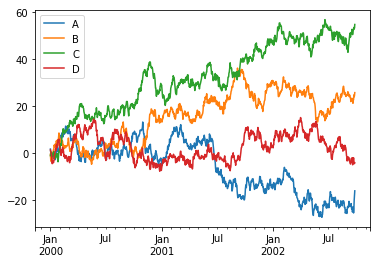

In [77]:
import matplotlib.pyplot as plt

pdf=pd.DataFrame(np.random.randn(1000, 4), index=ts.index,columns=['A', 'B', 'C', 'D'])
pdf = pdf.cumsum()
plt.figure(); pdf.plot(); plt.legend(loc='best')